In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import os


BUCKET_DIR  = 'TV_buckets'
FNO_CKPT    = 'fno_modes64_38traj_seed0.pt'   # saved by FNO.ipynb
CNN_CKPT    = 'cnn_k3_best.pt'                # saved by cnn_full_pipeline.ipynb (one extra line, see below)
RESOLUTIONS = [128, 256, 512]
BUCKETS     = ['smooth', 'medium', 'rough']

# bucket code - roughness based followed by total variation, plots in this file are made based on roughness split

In [2]:
path = 'data/pdebench_burgers_core.npz'     # the file your bucketing code loads
output_folder = 'bucketed_sharpness'
RESOLUTIONS = [128, 256, 512]
NAMES = ['smooth', 'medium', 'rough']
REF_RES = 512                               # grid the score is measured on (finest = fronts best resolved)

data = np.load(path)
os.makedirs(output_folder, exist_ok=True)


def sharpness(u):
    """RMS slope / RMS of (u - mean u) for each row of u (batch, N), periodic grid on [0, 1)."""
    u = u.astype(np.float64)
    dx = 1.0 / u.shape[1]
    ux = (np.roll(u, -1, axis=1) - np.roll(u, 1, axis=1)) / (2 * dx)
    fluct = u - u.mean(axis=1, keepdims=True)
    return np.sqrt((ux ** 2).mean(axis=1)) / (np.sqrt((fluct ** 2).mean(axis=1)) + 1e-12)


def rel_l2(pred, target):
    return np.linalg.norm(pred - target, axis=1) / (np.linalg.norm(target, axis=1) + 1e-8)


# Rank once on the reference grid; keep each bucket's samples in their original row order
scores = sharpness(data[f'eval_{REF_RES}_field'])
buckets = {name: np.sort(idx) for name, idx in zip(NAMES, np.array_split(np.argsort(scores, kind='stable'), 3))}
labels = np.empty(len(scores), dtype=int)
for k, name in enumerate(NAMES):
    labels[buckets[name]] = k
edges = [(scores[buckets[lo]].max() + scores[buckets[hi]].min()) / 2 for lo, hi in zip(NAMES[:-1], NAMES[1:])]

for res in RESOLUTIONS:
    field, target = data[f'eval_{res}_field'], data[f'eval_{res}_target']
    context, coords = data[f'eval_{res}_context'], data[f'eval_{res}_coordinates']
    assert len(field) == len(scores), f"eval_{res} has a different number of samples than eval_{REF_RES}"
    for name, idx in buckets.items():
        np.savez(f'{output_folder}/eval_{res}_{name}.npz', field=field[idx], target=target[idx],
                 context=context[idx], coordinates=coords, indices=idx, sharpness=scores[idx])
    print(f"Resolution {res} - " + ", ".join(f"{n}: {len(i)}" for n, i in buckets.items()))

np.savez(f'{output_folder}/bucket_info.npz', sharpness=scores, labels=labels, edges=np.array(edges),
         ref_res=REF_RES, **{f'idx_{n}': i for n, i in buckets.items()})

# Check what was written: every bucket file must hold exactly the source rows it claims to
for res in RESOLUTIONS:
    for name in NAMES:
        with np.load(f'{output_folder}/eval_{res}_{name}.npz') as f:
            assert np.array_equal(f['field'], data[f'eval_{res}_field'][f['indices']])
            assert np.array_equal(f['target'], data[f'eval_{res}_target'][f['indices']])
print(f"\nSaved {len(RESOLUTIONS) * len(NAMES)} bucket files and bucket_info.npz to {output_folder}/ (contents verified)")

# Summary: score range, identity error (how much each bucket changes in one step) and the sample numbers
print(f"Sharpness scored at {REF_RES}; bucket edges at R = " + ", ".join(f"{e:.2f}" for e in edges) + "\n")
print(f"{'bucket':<8}{'R range':>17}" + "".join(f"{f'identity @{r}':>15}" for r in RESOLUTIONS))
for name, idx in buckets.items():
    ids = [rel_l2(data[f'eval_{r}_field'][idx], data[f'eval_{r}_target'][idx]).mean() for r in RESOLUTIONS]
    print(f"{name:<8}{f'{scores[idx].min():.2f} - {scores[idx].max():.2f}':>17}" + "".join(f"{v:>15.6f}" for v in ids))
print()
for name, idx in buckets.items():
    print(f"{name:<8} samples: {', '.join(map(str, idx))}")

Resolution 128 - smooth: 20, medium: 20, rough: 20
Resolution 256 - smooth: 20, medium: 20, rough: 20
Resolution 512 - smooth: 20, medium: 20, rough: 20

Saved 9 bucket files and bucket_info.npz to bucketed_sharpness/ (contents verified)
Sharpness scored at 512; bucket edges at R = 14.79, 21.73

bucket            R range  identity @128  identity @256  identity @512
smooth       7.72 - 14.42       0.013185       0.013184       0.013184
medium      15.16 - 21.47       0.022519       0.022518       0.022517
rough       22.00 - 52.73       0.061900       0.061944       0.061956

smooth   samples: 1, 4, 9, 10, 18, 19, 20, 23, 24, 28, 29, 32, 33, 34, 38, 39, 43, 44, 48, 49
medium   samples: 2, 3, 7, 8, 12, 13, 14, 17, 21, 22, 31, 37, 40, 42, 51, 52, 53, 54, 58, 59
rough    samples: 0, 5, 6, 11, 15, 16, 25, 26, 27, 30, 35, 36, 41, 45, 46, 47, 50, 55, 56, 57


## below plots explaining why total variation methods may not be reliable

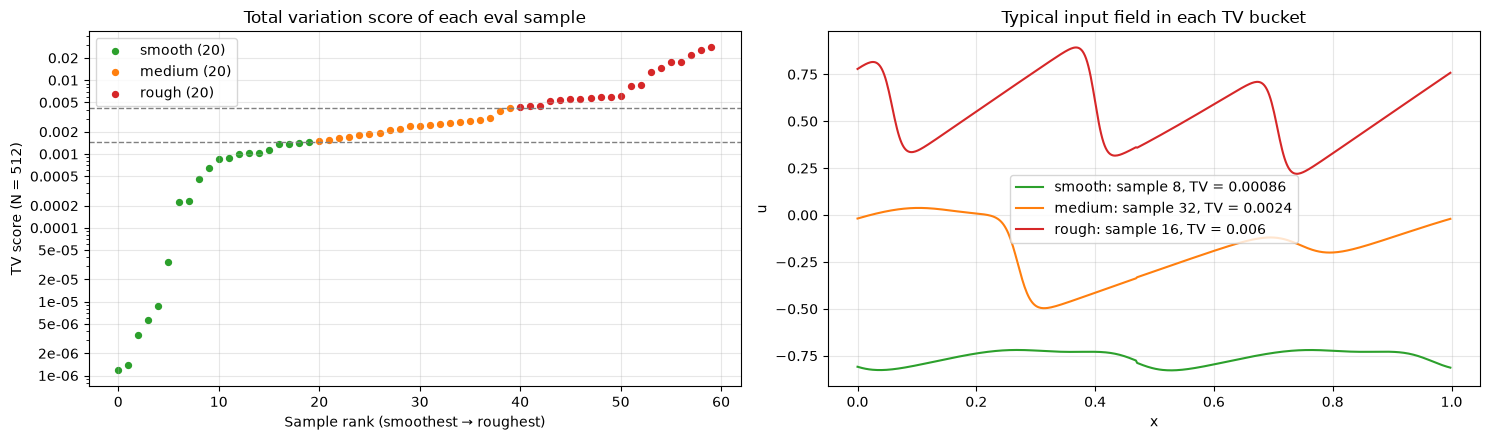

In [4]:
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

TV_DIR = 'TV_buckets'
BUCKET_COLORS = {'smooth': 'C2', 'medium': 'C1', 'rough': 'C3'}

def tv_score(u):
    """Total variation per grid step, the score the TV buckets were ranked by: mean |u[i+1] - u[i]|."""
    return np.mean(np.abs(np.diff(u, axis=1)), axis=1)

# The TV files don't store scores or sample numbers, so work them out from the fields:
# score each sample, and find its row in the original eval set
all_fields = np.load('data/pdebench_burgers_core.npz')['eval_512_field']
tv = {}
for b in BUCKETS:
    field = np.load(f'{TV_DIR}/eval_512_{b}.npz')['field']
    index = [int(np.flatnonzero((all_fields == row).all(axis=1))[0]) for row in field]
    tv[b] = dict(field=field, score=tv_score(field), index=index)
edges = [(tv[lo]['score'].max() + tv[hi]['score'].min()) / 2 for lo, hi in zip(BUCKETS[:-1], BUCKETS[1:])]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# left: every eval sample's TV score, smoothest to roughest, coloured by bucket
start = 0
for b in BUCKETS:
    s = np.sort(tv[b]['score'])
    axes[0].scatter(np.arange(start, start + len(s)), s, s=18, color=BUCKET_COLORS[b], label=f'{b} ({len(s)})')
    start += len(s)
for e in edges:
    axes[0].axhline(e, color='gray', ls='--', lw=1)
axes[0].set_yscale('log')
axes[0].yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
axes[0].yaxis.set_minor_formatter(NullFormatter())
axes[0].set_xlabel('Sample rank (smoothest → roughest)')
axes[0].set_ylabel('TV score (N = 512)')
axes[0].set_title('Total variation score of each eval sample')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# right: the sample with the middle score in each bucket, on the 512 grid
for b in BUCKETS:
    k = np.argsort(tv[b]['score'])[len(tv[b]['score']) // 2]
    x = np.linspace(0, 1, tv[b]['field'].shape[1], endpoint=False)
    axes[1].plot(x, tv[b]['field'][k], color=BUCKET_COLORS[b],
                 label=f"{b}: sample {tv[b]['index'][k]}, TV = {tv[b]['score'][k]:.2g}")
axes[1].set_xlabel('x')
axes[1].set_ylabel('u')
axes[1].set_title('Typical input field in each TV bucket')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## two model classes

In [5]:
def make_input(u):
    """(batch, N) -> (batch, N, 2): the value u and its position x in [0, 1)."""
    batch, n_points = u.shape
    x = torch.linspace(0, 1, n_points + 1, device=u.device)[:-1]
    x = x.expand(batch, n_points)
    return torch.stack([u, x], dim=-1)


class SpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (in_channels * out_channels)
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, modes, dtype=torch.cfloat))

    def forward(self, x):
        batch, _, n_points = x.shape
        x_freq = torch.fft.rfft(x)
        out_freq = torch.zeros(batch, self.weights.shape[1], n_points // 2 + 1,
                               dtype=torch.cfloat, device=x.device)
        k = min(self.modes, n_points // 2 + 1)
        out_freq[:, :, :k] = torch.einsum("bix,iox->box", x_freq[:, :, :k], self.weights[:, :, :k])
        return torch.fft.irfft(out_freq, n=n_points)


class FNO1d(nn.Module):
    def __init__(self, modes=64, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.w    = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))

    def forward(self, x):
        x = self.lift(x).permute(0, 2, 1)
        for fourier, local in zip(self.spec, self.w):
            x = nn.functional.gelu(fourier(x) + local(x))
        x = x.permute(0, 2, 1)
        return self.proj(x).squeeze(-1)


class GridLockedCNN(nn.Module):
    def __init__(self, hidden=64, kernel_size=3, num_layers=4):
        super().__init__()
        layers = [nn.Conv1d(1, hidden, kernel_size, padding=kernel_size // 2,
                            padding_mode='circular'), nn.ReLU()]
        for _ in range(num_layers - 1):
            layers += [nn.Conv1d(hidden, hidden, kernel_size, padding=kernel_size // 2,
                                 padding_mode='circular'), nn.ReLU()]
        layers.append(nn.Conv1d(hidden, 1, kernel_size, padding=kernel_size // 2,
                                padding_mode='circular'))
        self.net = nn.Sequential(*layers)

    def forward(self, u):
        return u + self.net(u)

## loading the trained weights

In [6]:
ckpt = torch.load(FNO_CKPT, map_location='cpu', weights_only=False)
fno = FNO1d(**ckpt['config'])
fno.load_state_dict(ckpt['state'])
fno.eval()

ckpt = torch.load(CNN_CKPT, map_location='cpu', weights_only=False)
cnn = GridLockedCNN(**ckpt['config'])
cnn.load_state_dict(ckpt['state'])
cnn.eval()

print('both models loaded')

both models loaded


## Each model makes a prediction and return u-next in desired shape

In [7]:
def predict_fno(u_now):
    with torch.no_grad():
        u = torch.tensor(u_now, dtype=torch.float32)
        return fno(make_input(u)).numpy()                 # (samples, N, 2) in -> (samples, N) out


def predict_cnn(u_now):
    with torch.no_grad():
        u = torch.tensor(u_now, dtype=torch.float32)
        return cnn(u[:, None, :])[:, 0, :].numpy()        # (samples, 1, N) in -> (samples, N) out

## Scoring the pred

In [8]:
def rel_l2(pred, true):
    mistake = np.linalg.norm(pred - true, axis=1)
    size    = np.linalg.norm(true, axis=1) + 1e-8
    return mistake / size

## Running both models on every bucket

For each of the 9 bucket files: load it, predict with both models, score each prediction against the true u_next.

In [9]:
err  = {m: {b: {} for b in BUCKETS} for m in ['FNO', 'CNN', 'Identity']}
pred = {m: {b: {} for b in BUCKETS} for m in ['FNO', 'CNN']}
data = {b: {} for b in BUCKETS}                       # keep inputs/answers for the example plot

for b in BUCKETS:
    for res in RESOLUTIONS:
        f = np.load(f'{BUCKET_DIR}/eval_{res}_{b}.npz')
        u_now, u_next = f['field'], f['target']        # (20, res) each
        data[b][res] = dict(u_now=u_now, u_next=u_next
                            #sharpness=f['sharpness']
                           )

        pred['FNO'][b][res] = predict_fno(u_now)
        pred['CNN'][b][res] = predict_cnn(u_now)

        err['FNO'][b][res]      = rel_l2(pred['FNO'][b][res], u_next)
        err['CNN'][b][res]      = rel_l2(pred['CNN'][b][res], u_next)
        err['Identity'][b][res] = rel_l2(u_now, u_next)

        print(f"{b:<7}{res:>4} pts, {len(u_now)} samples   "
              f"FNO {err['FNO'][b][res].mean():.5f}   CNN {err['CNN'][b][res].mean():.5f}")

smooth  128 pts, 20 samples   FNO 0.00038   CNN 0.00022
smooth  256 pts, 20 samples   FNO 0.00118   CNN 0.00218
smooth  512 pts, 20 samples   FNO 0.00136   CNN 0.00322
medium  128 pts, 20 samples   FNO 0.00112   CNN 0.00070
medium  256 pts, 20 samples   FNO 0.00240   CNN 0.01029
medium  512 pts, 20 samples   FNO 0.00273   CNN 0.01483
rough   128 pts, 20 samples   FNO 0.00894   CNN 0.00741
rough   256 pts, 20 samples   FNO 0.00940   CNN 0.03953
rough   512 pts, 20 samples   FNO 0.00955   CNN 0.05719


In [10]:
# Check: averaged over all 60 samples this should match the model notebooks
# (FNO 0.003480 / 0.004325 / 0.004549,  CNN 0.002776 / 0.017335 / 0.025076)
for m in ['FNO', 'CNN']:
    overall = [np.concatenate([err[m][b][r] for b in BUCKETS]).mean() for r in RESOLUTIONS]
    print(m, '  '.join(f'{v:.6f}' for v in overall))

FNO 0.003480  0.004325  0.004549
CNN 0.002776  0.017335  0.025076


## Step 6: results table

Mean error over each bucket's 20 samples. `growth` = error at 512 / error at 128: 1.0 means the model works just as well on the finer grid.

In [11]:
print(f"{'model':<10}{'bucket':<8}" + ''.join(f'{r:>10}' for r in RESOLUTIONS) + f"{'growth':>10}")
for m in ['FNO', 'CNN', 'Identity']:
    for b in BUCKETS:
        means = [err[m][b][r].mean() for r in RESOLUTIONS]
        print(f'{m:<10}{b:<8}' + ''.join(f'{v:>10.5f}' for v in means) + f'{means[-1] / means[0]:>9.2f}x')
    print()

print('Samples (out of 20) where the FNO is closer to u_next than the CNN')
for b in BUCKETS:
    wins = [int(np.sum(err['FNO'][b][r] < err['CNN'][b][r])) for r in RESOLUTIONS]
    print(f'{b:<8}' + '   '.join(f'{r} pts: {w}/20' for r, w in zip(RESOLUTIONS, wins)))

model     bucket         128       256       512    growth
FNO       smooth     0.00038   0.00118   0.00136     3.63x
FNO       medium     0.00112   0.00240   0.00273     2.44x
FNO       rough      0.00894   0.00940   0.00955     1.07x

CNN       smooth     0.00022   0.00218   0.00322    14.36x
CNN       medium     0.00070   0.01029   0.01483    21.33x
CNN       rough      0.00741   0.03953   0.05719     7.72x

Identity  smooth     0.00423   0.00423   0.00423     1.00x
Identity  medium     0.01915   0.01915   0.01915     1.00x
Identity  rough      0.07422   0.07426   0.07427     1.00x

Samples (out of 20) where the FNO is closer to u_next than the CNN
smooth  128 pts: 4/20   256 pts: 12/20   512 pts: 12/20
medium  128 pts: 5/20   256 pts: 19/20   512 pts: 19/20
rough   128 pts: 10/20   256 pts: 20/20   512 pts: 20/20


## Step 7: plots

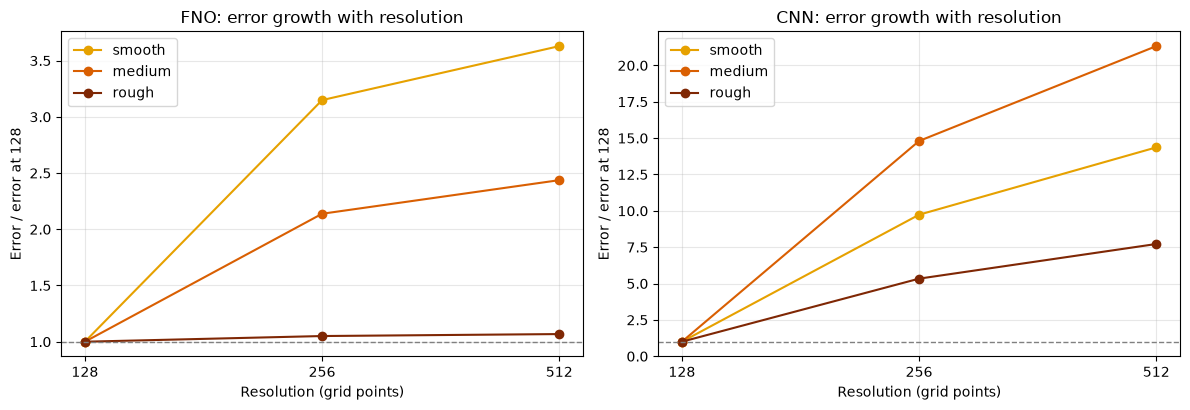

In [12]:
# Plot B: how each bucket's error changes as the grid gets finer (1.0 = no change from 128)
BUCKET_COLORS = {'smooth': '#e6a100', 'medium': '#d95f02', 'rough': '#7f2704'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, m in zip(axes, ['FNO', 'CNN']):
    for b in BUCKETS:
        growth = [err[m][b][r].mean() / err[m][b][128].mean() for r in RESOLUTIONS]
        ax.plot(RESOLUTIONS, growth, 'o-', color=BUCKET_COLORS[b], label=b)
    ax.axhline(1, color='gray', ls='--', lw=1)
    ax.set_xscale('log', base=2)
    ax.set_xticks(RESOLUTIONS)
    ax.set_xticklabels([str(r) for r in RESOLUTIONS])
    ax.minorticks_off()
    ax.set_xlabel('Resolution (grid points)')
    ax.set_ylabel('Error / error at 128')
    ax.set_title(f'{m}: error growth with resolution')
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

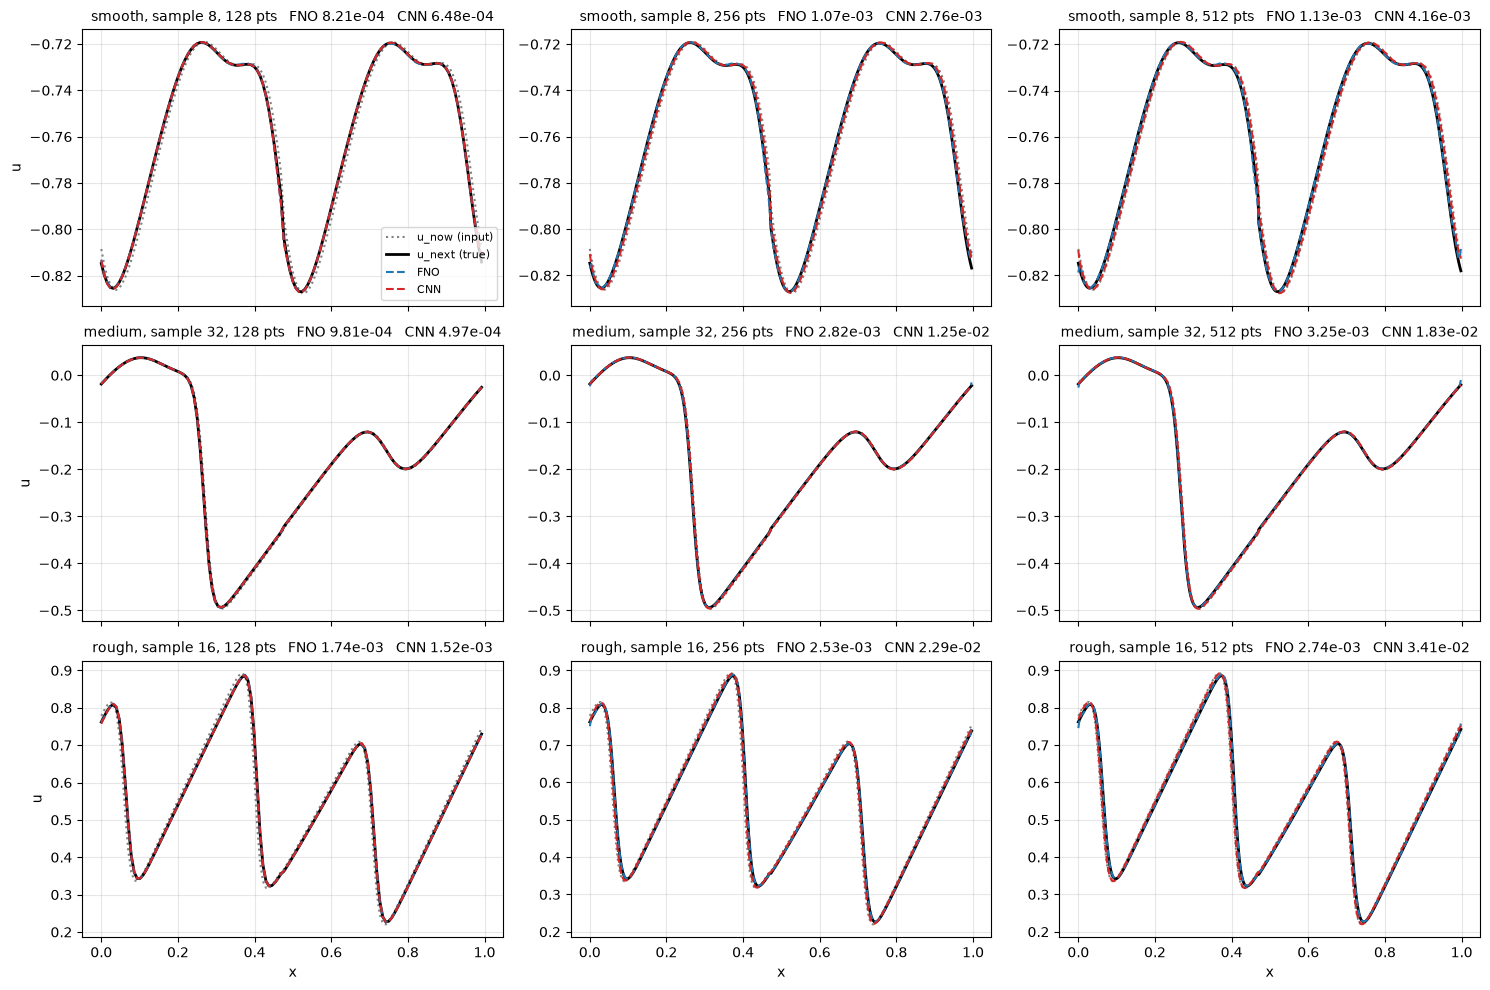

In [14]:
# Plot C (TV buckets): one typical sample per bucket (the one with the middle TV score), at all three resolutions
COLORS = {'FNO': '#1f77b4', 'CNN': '#d62728', 'Identity': '#9a9a9a'}

core = np.load('data/pdebench_burgers_core.npz')

def eval_index(rows, res):
    """Original eval-set number of each row, found by matching it in pdebench_burgers_core.npz."""
    all_rows = core[f'eval_{res}_field']
    return [int(np.flatnonzero((all_rows == r).all(axis=1))[0]) for r in rows]

fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for i, b in enumerate(BUCKETS):
    u512 = data[b][512]['u_now']
    tv = np.mean(np.abs(np.diff(u512, axis=1)), axis=1)
    sample = eval_index(u512, 512)[np.argsort(tv)[len(tv) // 2]]          # middle TV score in this bucket
    for j, res in enumerate(RESOLUTIONS):
        s = eval_index(data[b][res]['u_now'], res).index(sample)          # that same sample's row at this resolution
        ax = axes[i, j]
        xg = np.linspace(0, 1, res, endpoint=False)
        ax.plot(xg, data[b][res]['u_now'][s],  ':',  color='gray', label='u_now (input)')
        ax.plot(xg, data[b][res]['u_next'][s], '-',  color='k', lw=2, label='u_next (true)')
        ax.plot(xg, pred['FNO'][b][res][s],    '--', color=COLORS['FNO'], label='FNO')
        ax.plot(xg, pred['CNN'][b][res][s],    '--', color=COLORS['CNN'], label='CNN')
        ax.set_title(f"{b}, sample {sample}, {res} pts   FNO {err['FNO'][b][res][s]:.2e}   CNN {err['CNN'][b][res][s]:.2e}",
                     fontsize=10)
        ax.grid(True, alpha=0.3)
    axes[i, 0].set_ylabel('u')
for ax in axes[-1]:
    ax.set_xlabel('x')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## keeping x axis as u_next to see actual variaation

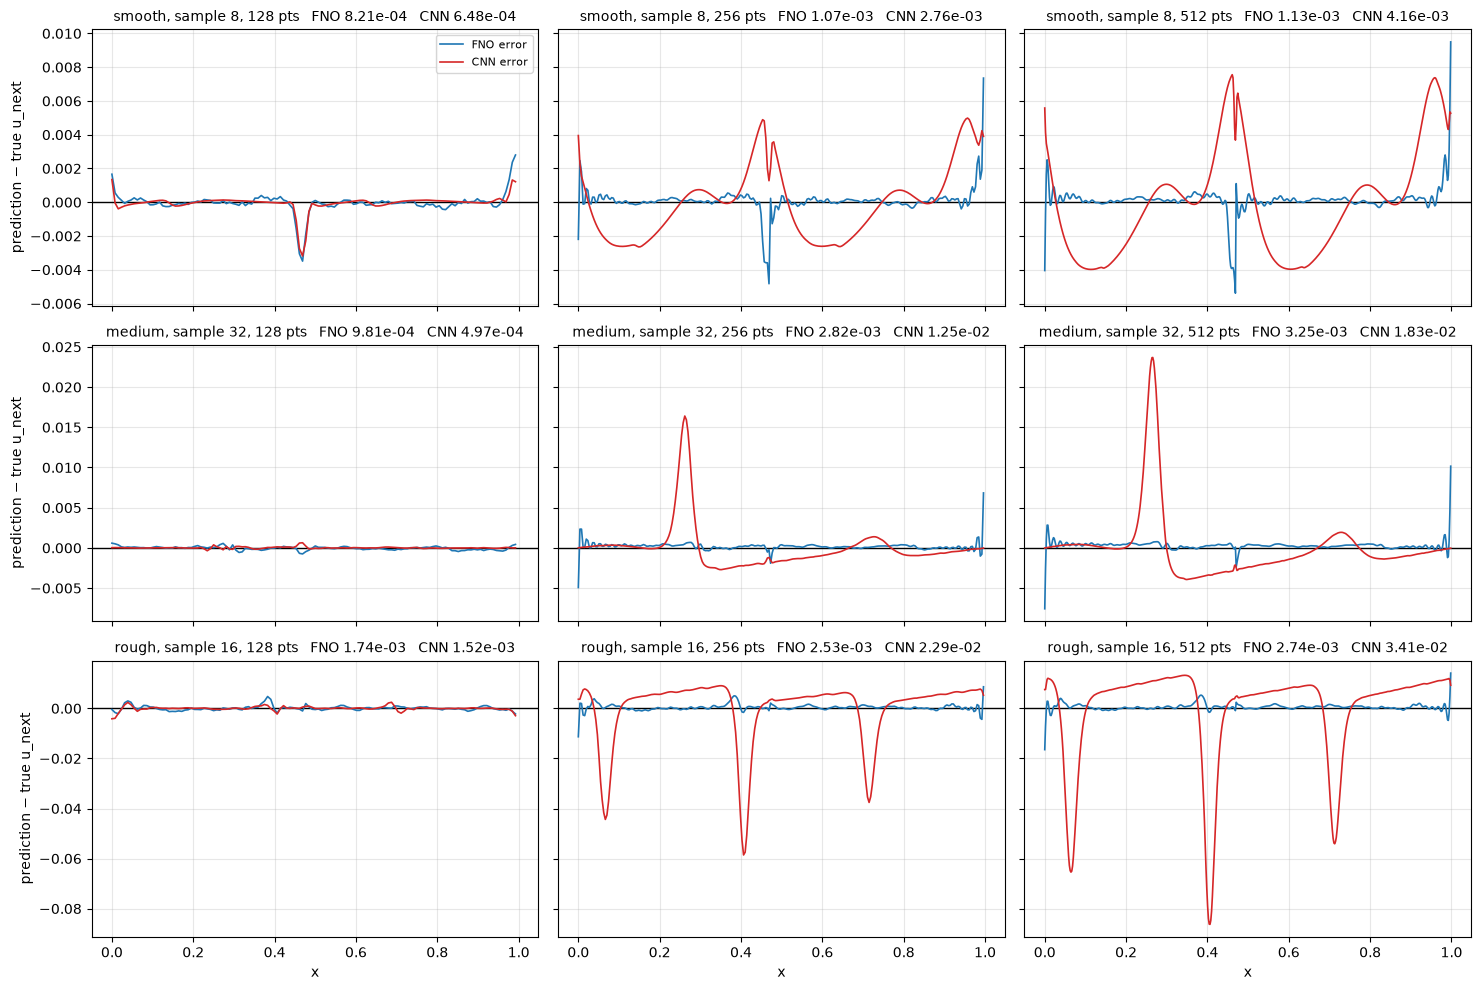

In [15]:
# Plot C2 (TV buckets): the same samples as Plot C, but showing each model's error (prediction - true u_next)
core = np.load('data/pdebench_burgers_core.npz')

def eval_index(rows, res):
    """Original eval-set number of each row, found by matching it in pdebench_burgers_core.npz."""
    all_rows = core[f'eval_{res}_field']
    return [int(np.flatnonzero((all_rows == r).all(axis=1))[0]) for r in rows]

fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True, sharey='row')
for i, b in enumerate(BUCKETS):
    u512 = data[b][512]['u_now']
    tv = np.mean(np.abs(np.diff(u512, axis=1)), axis=1)
    sample = eval_index(u512, 512)[np.argsort(tv)[len(tv) // 2]]          # middle TV score in this bucket
    for j, res in enumerate(RESOLUTIONS):
        s = eval_index(data[b][res]['u_now'], res).index(sample)          # that same sample's row at this resolution
        ax = axes[i, j]
        xg = np.linspace(0, 1, res, endpoint=False)
        u_next = data[b][res]['u_next'][s]
        ax.axhline(0, color='k', lw=1)
        ax.plot(xg, pred['FNO'][b][res][s] - u_next, color=COLORS['FNO'], lw=1.2, label='FNO error')
        ax.plot(xg, pred['CNN'][b][res][s] - u_next, color=COLORS['CNN'], lw=1.2, label='CNN error')
        ax.set_title(f"{b}, sample {sample}, {res} pts   FNO {err['FNO'][b][res][s]:.2e}   CNN {err['CNN'][b][res][s]:.2e}",
                     fontsize=10)
        ax.grid(True, alpha=0.3)
    axes[i, 0].set_ylabel('prediction − true u_next')
for ax in axes[-1]:
    ax.set_xlabel('x')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

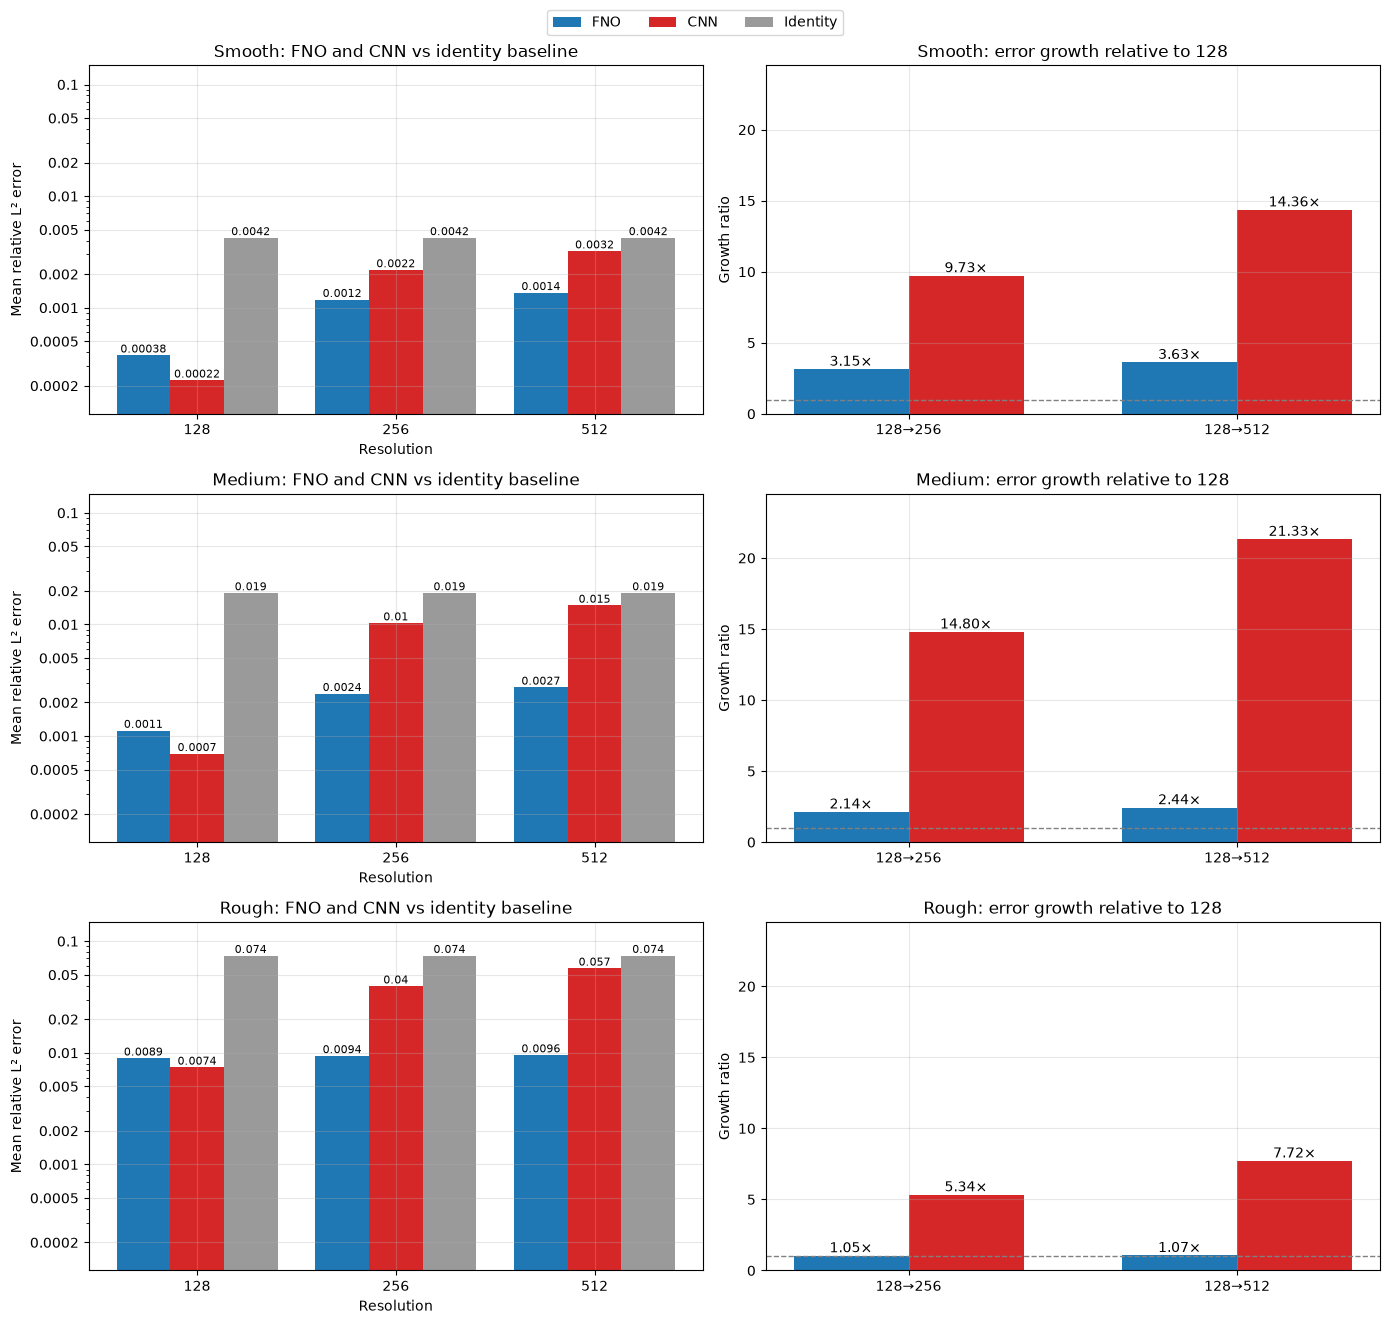

In [16]:
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

COLORS = {'FNO': '#1f77b4', 'CNN': '#d62728', 'Identity': '#9a9a9a'}

growth = {m: {b: [err[m][b][r].mean() / err[m][b][128].mean() for r in RESOLUTIONS[1:]] for b in BUCKETS}
          for m in ['FNO', 'CNN']}
all_means = [err[m][b][r].mean() for m in ['FNO', 'CNN', 'Identity'] for b in BUCKETS for r in RESOLUTIONS]

fig, axes = plt.subplots(len(BUCKETS), 2, figsize=(14, 13))
for row, b in enumerate(BUCKETS):
    # left: mean error at each resolution
    ax = axes[row, 0]
    x, w = np.arange(len(RESOLUTIONS)), 0.27
    for k, m in enumerate(['FNO', 'CNN', 'Identity']):
        xs = x + (k - 1) * w
        means = [err[m][b][r].mean() for r in RESOLUTIONS]
        ax.bar(xs, means, w, color=COLORS[m], label=m)
        for xi, v in zip(xs, means):
            ax.text(xi, v, f'{v:.2g}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([str(r) for r in RESOLUTIONS])
    ax.set_xlabel('Resolution')
    ax.set_ylabel('Mean relative L² error')
    ax.set_yscale('log')
    ax.set_ylim(min(all_means) * 0.5, max(all_means) * 2)
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_title(f'{b.capitalize()}: FNO and CNN vs identity baseline')
    ax.grid(True, alpha=0.3)

    # right: error at 256 and 512 divided by error at 128
    ax = axes[row, 1]
    x, w = np.arange(len(RESOLUTIONS) - 1), 0.35
    for k, m in enumerate(['FNO', 'CNN']):
        xs = x + (k - 0.5) * w
        ax.bar(xs, growth[m][b], w, color=COLORS[m])
        for xi, v in zip(xs, growth[m][b]):
            ax.text(xi, v, f'{v:.2f}×', ha='center', va='bottom')
    ax.axhline(1, color='gray', ls='--', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f'128→{r}' for r in RESOLUTIONS[1:]])
    ax.set_ylabel('Growth ratio')
    ax.set_ylim(0, max(max(g) for m in growth for g in growth[m].values()) * 1.15)
    ax.set_title(f'{b.capitalize()}: error growth relative to 128')
    ax.grid(True, alpha=0.3)

fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

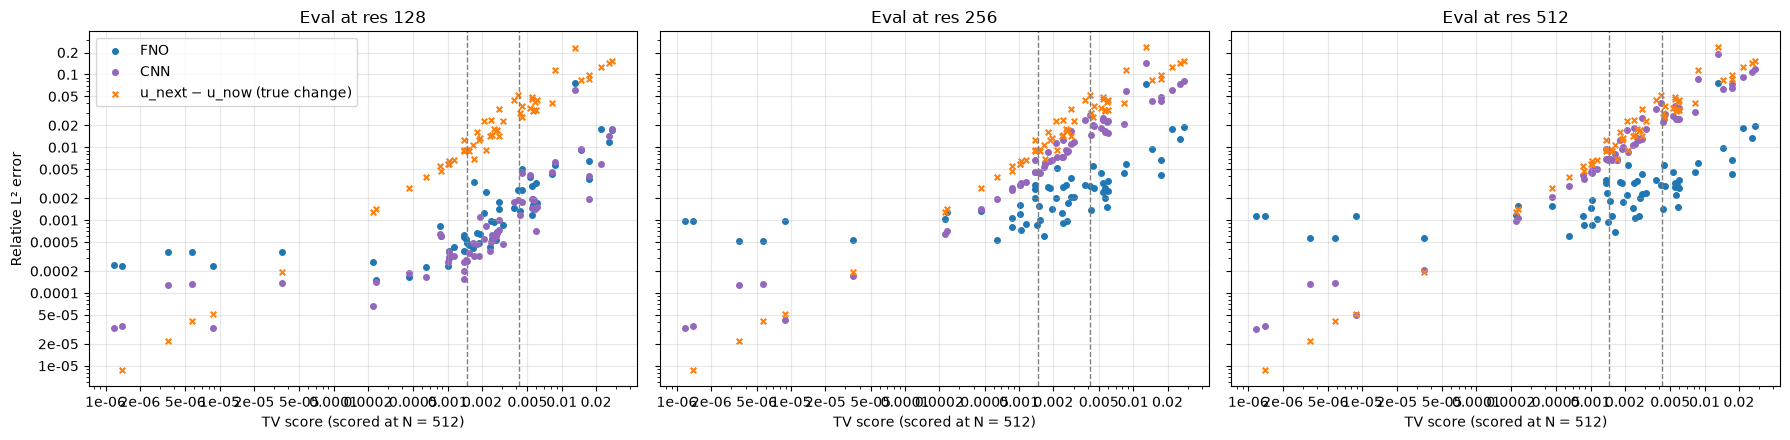

In [17]:
# Error vs TV score for every sample (TV buckets)
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

core = np.load('data/pdebench_burgers_core.npz')

def eval_index(rows, res):
    """Original eval-set number of each row, found by matching it in pdebench_burgers_core.npz."""
    all_rows = core[f'eval_{res}_field']
    return [int(np.flatnonzero((all_rows == r).all(axis=1))[0]) for r in rows]

tv512 = np.mean(np.abs(np.diff(core['eval_512_field'], axis=1)), axis=1)    # TV score of every eval sample, 512 grid

# x position of every row at every resolution: that sample's 512 TV score
# (the TV files are sorted per resolution, so rows must be matched one resolution at a time)
score = {res: {b: tv512[eval_index(data[b][res]['u_now'], res)] for b in BUCKETS} for res in RESOLUTIONS}
edges = [(score[512][lo].max() + score[512][hi].min()) / 2 for lo, hi in zip(BUCKETS[:-1], BUCKETS[1:])]

STYLE = {'FNO':      dict(color='C0', marker='o', label='FNO'),
         'CNN':      dict(color='C4', marker='o', label='CNN'),
         'Identity': dict(color='C1', marker='x', label='u_next − u_now (true change)')}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, res in zip(axes, RESOLUTIONS):
    x_all = np.concatenate([score[res][b] for b in BUCKETS])
    for m in ['FNO', 'CNN', 'Identity']:
        y_all = np.concatenate([err[m][b][res] for b in BUCKETS])
        ax.scatter(x_all, y_all, s=16, **STYLE[m])
    for e in edges:
        ax.axvline(e, color='gray', ls='--', lw=1)
    ax.set_xscale('log')
    ax.set_yscale('log')
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
        axis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
        axis.set_minor_formatter(NullFormatter())
    ax.set_xlabel('TV score (scored at N = 512)')
    ax.set_title(f'Eval at res {res}')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('Relative L² error')
axes[0].legend()
plt.tight_layout()
plt.show()

the farthur it is from orange plottings, the better the output of the model